In [2]:
!pip install -q transformers datasets accelerate scikit-learn pandas matplotlib


In [5]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA disponível:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("Memória GPU:", round(
        torch.cuda.get_device_properties(0).total_memory / 1024**3, 2
    ), "GB")

PyTorch: 2.14.1+cu130
CUDA disponível: True
GPU: Tesla T4
Memória GPU: 14.56 GB


In [6]:
import os
from getpass import getpass

hf_token = getpass("Cole seu token Hugging Face: ")
os.environ["HF_TOKEN"] = hf_token

print("Token configurado:", bool(hf_token))

Cole seu token Hugging Face: ··········
Token configurado: True


In [7]:
import torch
from transformers import AutoModelForCausalLM, AutoTokenizer

MODEL_ID = "meta-llama/Llama-3.2-1B"

tokenizer = AutoTokenizer.from_pretrained(
    MODEL_ID,
    token=hf_token
)

model = AutoModelForCausalLM.from_pretrained(
    MODEL_ID,
    token=hf_token,
    torch_dtype=torch.float16,
    device_map="auto",
    attn_implementation="eager"
)

model.eval()

print("Modelo carregado:", MODEL_ID)
print("Dispositivo:", model.get_input_embeddings().weight.device)
print("Camadas:", model.config.num_hidden_layers)

config.json:   0%|          | 0.00/843 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/50.5k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/9.09M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/301 [00:00<?, ?B/s]

[transformers] `torch_dtype` is deprecated! Use `dtype` instead!


model.safetensors: reconstructing file:   0%|          |  0.00B / 2.47GB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/146 [00:00<?, ?it/s]

generation_config.json:   0%|          | 0.00/185 [00:00<?, ?B/s]

Modelo carregado: meta-llama/Llama-3.2-1B
Dispositivo: cuda:0
Camadas: 16


In [8]:
prompt = "Explique o que é inteligência artificial em uma frase."

inputs = tokenizer(prompt, return_tensors="pt").to("cuda")

with torch.no_grad():
    outputs = model.generate(
        **inputs,
        max_new_tokens=100,
        do_sample=False
    )

print(tokenizer.decode(outputs[0], skip_special_tokens=True))

[transformers] Ignoring clean_up_tokenization_spaces=True for BPE tokenizer TokenizersBackend. The clean_up_tokenization post-processing step is designed for WordPiece tokenizers and is destructive for BPE (it strips spaces before punctuation). Set clean_up_tokenization_spaces=False to suppress this warning, or set clean_up_tokenization_spaces_for_bpe_even_though_it_will_corrupt_output=True to force cleanup anyway.


Explique o que é inteligência artificial em uma frase. 1. A inteligência artificial é a capacidade de um computador de aprender, pensar e agir de forma inteligente. 2. A inteligência artificial é a capacidade de um computador de aprender, pensar e agir de forma inteligente. 3. A inteligência artificial é a capacidade de um computador de aprender, pensar e agir de forma inteligente. 4. A inteligência artificial é a capacidade de um computador de aprender, pensar


In [9]:
# Congelar todos os parâmetros do modelo
for param in model.parameters():
    param.requires_grad = False

# Verificar parâmetros congelados
total = sum(p.numel() for p in model.parameters())
treinaveis = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

print("Total de parâmetros:", total)
print("Parâmetros treináveis:", treinaveis)
print("Parâmetros congelados:", total - treinaveis)

Total de parâmetros: 1235814400
Parâmetros treináveis: 0
Parâmetros congelados: 1235814400


In [10]:
import torch.nn as nn

# Nova camada de classificação
model.classification_head = nn.Linear(
    model.config.hidden_size, 2
).to(model.get_input_embeddings().weight.device)

# Tornar somente a nova camada treinável
for param in model.classification_head.parameters():
    param.requires_grad = True

# Contabilizar parâmetros
total = sum(p.numel() for p in model.parameters())
treinaveis = sum(
    p.numel() for p in model.parameters()
    if p.requires_grad
)

print("Total de parâmetros:", total)
print("Parâmetros treináveis:", treinaveis)
print("Parâmetros congelados:", total - treinaveis)

Total de parâmetros: 1235818498
Parâmetros treináveis: 4098
Parâmetros congelados: 1235814400


In [11]:
print(model.classification_head)
print("Parâmetros da nova camada:",
      sum(p.numel() for p in model.classification_head.parameters()))

Linear(in_features=2048, out_features=2, bias=True)
Parâmetros da nova camada: 4098


In [13]:
from datasets import load_dataset

# Carregar dataset IMDb pelo identificador completo
dataset = load_dataset("stanfordnlp/imdb")

# Selecionar amostras aleatórias
treino = dataset["train"].shuffle(seed=42).select(range(400))
teste = dataset["test"].shuffle(seed=42).select(range(100))

print("Avaliações para treinamento:", len(treino))
print("Avaliações para teste:", len(teste))

print("\nExemplo de avaliação:")
print(treino[0]["text"][:500])

print("\nSentimento:", "Positivo" if treino[0]["label"] == 1 else "Negativo")

README.md:   0%|          | 0.00/7.81k [00:00<?, ?B/s]

plain_text/train-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 21.0MB            

plain_text/train-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/test-00000-of-00001.parquet: reconstructing file:   0%|          |  0.00B / 20.5MB            

plain_text/test-00000-of-00001.parquet: downloading bytes:           |  0.00B            

plain_text/unsupervised-00000-of-00001.p(…): reconstructing file:   0%|          |  0.00B / 42.0MB            

plain_text/unsupervised-00000-of-00001.p(…): downloading bytes:           |  0.00B            

Generating train split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating test split:   0%|          | 0/25000 [00:00<?, ? examples/s]

Generating unsupervised split:   0%|          | 0/50000 [00:00<?, ? examples/s]

Avaliações para treinamento: 400
Avaliações para teste: 100

Exemplo de avaliação:
There is no relation at all between Fortier and Profiler but the fact that both are police series about violent crimes. Profiler looks crispy, Fortier looks classic. Profiler plots are quite simple. Fortier's plot are far more complicated... Fortier looks more like Prime Suspect, if we have to spot similarities... The main character is weak and weirdo, but have "clairvoyance". People like to compare, to judge, to evaluate. How about just enjoying? Funny thing too, people writing Fortier looks Am

Sentimento: Positivo


In [14]:
# Preparar o tokenizer para classificação
tokenizer.pad_token = tokenizer.eos_token
tokenizer.padding_side = "right"

print("Tokenizer preparado!")
print("Token de preenchimento:", tokenizer.pad_token)
print("Camada classificadora:", model.classification_head)

Tokenizer preparado!
Token de preenchimento: <|end_of_text|>
Camada classificadora: Linear(in_features=2048, out_features=2, bias=True)


In [15]:
# Extrair características usando o Llama congelado

import torch
from torch.utils.data import DataLoader

def extrair_caracteristicas(dados, batch_size=8):
    features = []
    labels = []

    model.eval()

    for inicio in range(0, len(dados), batch_size):
        lote = dados[inicio:inicio + batch_size]

        textos = lote["text"]
        entradas = tokenizer(
            textos,
            padding=True,
            truncation=True,
            max_length=256,
            return_tensors="pt"
        ).to("cuda")

        with torch.no_grad():
            saida = model(
                **entradas,
                output_hidden_states=True,
                return_dict=True
            )

            ocultos = saida.hidden_states[-1]

            mascara = entradas["attention_mask"].unsqueeze(-1)

            representacao = (
                (ocultos * mascara).sum(dim=1)
                / mascara.sum(dim=1).clamp(min=1)
            )

        features.append(representacao.cpu())
        labels.extend(lote["label"])

    return torch.cat(features), torch.tensor(labels)

# Extrair dados de treinamento e teste
X_train, y_train = extrair_caracteristicas(treino)
X_test, y_test = extrair_caracteristicas(teste)

print("Características de treinamento:", X_train.shape)
print("Características de teste:", X_test.shape)

Características de treinamento: torch.Size([400, 2048])
Características de teste: torch.Size([100, 2048])


In [18]:
# Treinar somente a nova camada classificadora

import torch.nn as nn
import torch.optim as optim

device = "cuda"

model.classification_head.train()

optimizer = optim.AdamW(
    model.classification_head.parameters(),
    lr=1e-3
)

criterion = nn.CrossEntropyLoss()

X_train = X_train.to(device)
y_train = y_train.to(device)

epocas = 20

for epoca in range(epocas):
    optimizer.zero_grad()

    saidas = model.classification_head(X_train)
    loss = criterion(saidas, y_train)

    loss.backward()
    optimizer.step()

    print(f"Época {epoca+1}/{epocas} - Loss: {loss.item():.4f}")

print("Treinamento concluído!")

Época 1/20 - Loss: 0.7564
Época 2/20 - Loss: 2.1440
Época 3/20 - Loss: 0.8937
Época 4/20 - Loss: 1.1060
Época 5/20 - Loss: 1.4125
Época 6/20 - Loss: 1.0223
Época 7/20 - Loss: 0.5816
Época 8/20 - Loss: 0.7577
Época 9/20 - Loss: 0.9676
Época 10/20 - Loss: 0.8448
Época 11/20 - Loss: 0.5707
Época 12/20 - Loss: 0.4951
Época 13/20 - Loss: 0.6364
Época 14/20 - Loss: 0.6995
Época 15/20 - Loss: 0.5968
Época 16/20 - Loss: 0.4542
Época 17/20 - Loss: 0.4277
Época 18/20 - Loss: 0.5006
Época 19/20 - Loss: 0.5356
Época 20/20 - Loss: 0.4801
Treinamento concluído!


In [17]:
# Corrigir compatibilidade de tipos numéricos

X_train = X_train.to(device="cuda", dtype=torch.float32)
X_test = X_test.to(device="cuda", dtype=torch.float32)

y_train = y_train.to(device="cuda", dtype=torch.long)
y_test = y_test.to(device="cuda", dtype=torch.long)

model.classification_head = model.classification_head.float()

print("Tipos corrigidos!")
print("Características:", X_train.dtype)
print("Camada:", next(model.classification_head.parameters()).dtype)

Tipos corrigidos!
Características: torch.float32
Camada: torch.float32


In [19]:
model.classification_head.eval()

with torch.no_grad():
    X_test = X_test.to(device)
    y_test = y_test.to(device)

    saidas = model.classification_head(X_test)
    previsoes = torch.argmax(saidas, dim=1)

    corretos = (previsoes == y_test).sum().item()
    acuracia = corretos / len(y_test) * 100

print(f"Acurácia no teste: {acuracia:.2f}%")
print(f"Acertos: {corretos} de {len(y_test)}")

Acurácia no teste: 76.00%
Acertos: 76 de 100


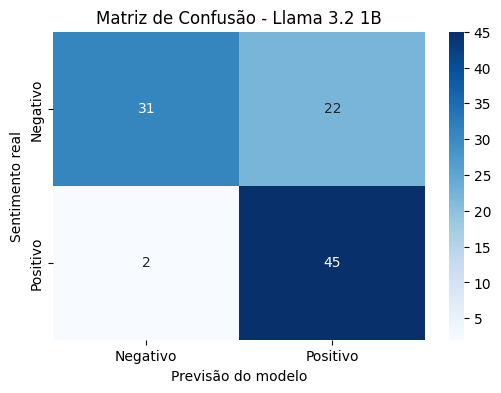

              precision    recall  f1-score   support

    Negativo       0.94      0.58      0.72        53
    Positivo       0.67      0.96      0.79        47

    accuracy                           0.76       100
   macro avg       0.81      0.77      0.76       100
weighted avg       0.81      0.76      0.75       100



In [20]:
from sklearn.metrics import confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

# Matriz de confusão
matriz = confusion_matrix(y_test.cpu().numpy(), previsoes.cpu().numpy())

plt.figure(figsize=(6, 4))
sns.heatmap(
    matriz,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Negativo", "Positivo"],
    yticklabels=["Negativo", "Positivo"]
)

plt.xlabel("Previsão do modelo")
plt.ylabel("Sentimento real")
plt.title("Matriz de Confusão - Llama 3.2 1B")
plt.show()

print(classification_report(
    y_test.cpu().numpy(),
    previsoes.cpu().numpy(),
    target_names=["Negativo", "Positivo"]
))